## AI - Based Road Accident Severity Prediction

## Project Overview

The main objective of this project is to predict the severity of road accidents using Deep Learning. The project uses the US Accidents dataset and an Artificial Neural Network (ANN) built with PyTorch.
The dataset contains accident-related information such as location, weather conditions, road features, temperature, humidity, wind speed, and accident time. These features are used to predict accident severity into four classes: Severity 1, Severity 2, Severity 3, and Severity 4.
The project includes data preprocessing, feature engineering, model training, validation, evaluation, and saving the trained model for future use in a Streamlit application.

In [1]:
import pandas as pd
import numpy as np
import os

In [2]:
file_path = r"C:\Users\BEST\Documents\Accident_Severity_DL\US_Accidents_March23.csv"

In [3]:
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("Dataset shape:", df.shape)
print("First 5 rows:")
display(df.head())

Dataset shape: (7728394, 46)
First 5 rows:


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-1,Source2,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Night
1,A-2,Source2,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Night,Night,Day
2,A-3,Source2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,NaN,NaN,0.01,...,False,False,False,False,True,False,Night,Night,Day,Day
3,A-4,Source2,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,NaN,NaN,0.01,...,False,False,False,False,False,False,Night,Day,Day,Day
4,A-5,Source2,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,NaN,NaN,0.01,...,False,False,False,False,True,False,Day,Day,Day,Day


## insight
The original dataset contains 7,728,394 rows and 46 columns.
Each row represents a road accident record.
The dataset contains accident-related information, including location, time, weather, and road conditions.

The dataset is large, so selecting a manageable subset helps reduce training time and computational requirements.

In [5]:
if "Severity" not in df.columns:
    raise ValueError("Severity column not found!")

print("Severity distribution:")
print(df["Severity"].value_counts().sort_index())

print("\nSeverity percentages:")
print((df["Severity"].value_counts(normalize=True).sort_index() * 100).round(2))

Severity distribution:
Severity
1      67366
2    6156981
3    1299337
4     204710
Name: count, dtype: int64

Severity percentages:
Severity
1     0.87
2    79.67
3    16.81
4     2.65
Name: proportion, dtype: float64


In [6]:
print("Severity 1 rows:", (df["Severity"] == 1).sum())
print("Severity 2 rows:", (df["Severity"] == 2).sum())
print("Severity 3 rows:", (df["Severity"] == 3).sum())
print("Severity 4 rows:", (df["Severity"] == 4).sum())

Severity 1 rows: 67366
Severity 2 rows: 6156981
Severity 3 rows: 1299337
Severity 4 rows: 204710


## Insight

Severity 2 is the most common class, while Severity 1 is the least common. This indicates a highly imbalanced dataset.

In [7]:
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values in Severity:", df["Severity"].isna().sum())
print("Severity data type:", df["Severity"].dtype)

Total rows: 7728394
Duplicate rows: 0

Missing values in Severity: 0
Severity data type: int64


In [8]:
## Balanced sample

## Reproducible sample: 50,000 rows per severity class
sample_size = 50000

df_balanced = (
    df.groupby("Severity", group_keys=False)
      .sample(n=sample_size, random_state=42)
      .reset_index(drop=True)
)

print("Balanced dataset shape:", df_balanced.shape)
print("\nSeverity counts:")
print(df_balanced["Severity"].value_counts().sort_index())

Balanced dataset shape: (200000, 46)

Severity counts:
Severity
1    50000
2    50000
3    50000
4    50000
Name: count, dtype: int64


## Insight
Balancing the training sample helps the model learn from all four severity classes instead of being dominated by the majority class.

In [9]:
print(df_balanced.columns.tolist())

['ID', 'Source', 'Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng', 'End_Lat', 'End_Lng', 'Distance(mi)', 'Description', 'Street', 'City', 'County', 'State', 'Zipcode', 'Country', 'Timezone', 'Airport_Code', 'Weather_Timestamp', 'Temperature(F)', 'Wind_Chill(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Direction', 'Wind_Speed(mph)', 'Precipitation(in)', 'Weather_Condition', 'Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Roundabout', 'Station', 'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Turning_Loop', 'Sunrise_Sunset', 'Civil_Twilight', 'Nautical_Twilight', 'Astronomical_Twilight']


## insight

inspected the available columns before selecting model features

In [10]:
## Select useful features for accident severity prediction

selected_columns = [
    'Severity',
    'Start_Time',
    'Start_Lat',
    'Start_Lng',
    'Distance(mi)',
    'Temperature(F)',
    'Humidity(%)',
    'Pressure(in)',
    'Visibility(mi)',
    'Wind_Direction',
    'Wind_Speed(mph)',
    'Precipitation(in)',
    'Weather_Condition',
    'Amenity',
    'Bump',
    'Crossing',
    'Give_Way',
    'Junction',
    'No_Exit',
    'Railway',
    'Roundabout',
    'Station',
    'Stop',
    'Traffic_Calming',
    'Traffic_Signal',
    'Turning_Loop',
    'Sunrise_Sunset'
]

df_model = df_balanced[selected_columns].copy()

print("Selected dataset shape:", df_model.shape)
print("\nMissing values:")
print(df_model.isnull().sum())

Selected dataset shape: (200000, 27)

Missing values:
Severity                 0
Start_Time               0
Start_Lat                0
Start_Lng                0
Distance(mi)             0
Temperature(F)        4554
Humidity(%)           4868
Pressure(in)          3849
Visibility(mi)        4910
Wind_Direction        4680
Wind_Speed(mph)      15155
Precipitation(in)    56725
Weather_Condition     4877
Amenity                  0
Bump                     0
Crossing                 0
Give_Way                 0
Junction                 0
No_Exit                  0
Railway                  0
Roundabout               0
Station                  0
Stop                     0
Traffic_Calming          0
Traffic_Signal           0
Turning_Loop             0
Sunrise_Sunset         895
dtype: int64


In [11]:
## Separate numerical and categorical columns


numerical_cols = df_model.select_dtypes(
    include=["number"]
).columns.drop("Severity")

categorical_cols = df_model.select_dtypes(
    include=["object", "category", "bool"]
).columns

## Fill numerical missing values with median
for col in numerical_cols:
    df_model[col] = df_model[col].fillna(
        df_model[col].median()
    )

## Fill categorical missing values with most frequent value
for col in categorical_cols:
    if df_model[col].isnull().any():
        df_model[col] = df_model[col].fillna(
            df_model[col].mode()[0]
        )

print("Remaining missing values:", df_model.isnull().sum().sum())

Remaining missing values: 0


## Training  and Testig Data Split

In [12]:
## Original dataset-il ninn 1% test data edukkunnu
df_test_raw = (
    df.groupby("Severity", group_keys=False)
      .sample(frac=0.01, random_state=42)
      .copy()
)

# Test data training-il varathirikkan
df_train_pool = df.drop(index=df_test_raw.index)

# Training-inayi balanced sample: oro class-ilum 50,000 rows
df_train_raw = (
    df_train_pool.groupby("Severity", group_keys=False)
      .sample(n=50000, random_state=42)
      .reset_index(drop=True)
)

df_test_raw = df_test_raw.reset_index(drop=True)

print("Training shape:", df_train_raw.shape)
print("Testing shape:", df_test_raw.shape)

print("\nTraining class counts:")
print(df_train_raw["Severity"].value_counts().sort_index())

print("\nTesting class distribution:")
print(df_test_raw["Severity"].value_counts(normalize=True).mul(100).round(2))

Training shape: (200000, 46)
Testing shape: (77284, 46)

Training class counts:
Severity
1    50000
2    50000
3    50000
4    50000
Name: count, dtype: int64

Testing class distribution:
Severity
2    79.67
3    16.81
4     2.65
1     0.87
Name: proportion, dtype: float64


## insight

The balanced training data helps with learning across classes, while the test set represents the original class imbalance more realistically.

## Feature Engineering

In [13]:

def prepare_features(data):
    data = data.copy()

    start_time = pd.to_datetime(
        data["Start_Time"],
        errors="coerce",
        utc=True
    )

    data["Start_Hour"] = start_time.dt.hour
    data["Start_Month"] = start_time.dt.month
    data["Start_DayOfWeek"] = start_time.dt.dayofweek

    data = data.drop(columns=["Start_Time"])

    return data

df_train_features = prepare_features(df_train_raw)
df_test_features = prepare_features(df_test_raw)

print("Training features shape:", df_train_features.shape)
print("Testing features shape:", df_test_features.shape)

print(df_train_features.head())

Training features shape: (200000, 48)
Testing features shape: (77284, 48)
          ID   Source  Severity             End_Time  Start_Lat   Start_Lng  \
0  A-2280659  Source2         1  2019-02-12 08:32:35  32.790001  -96.878212   
1  A-7187755  Source1         1  2020-04-20 18:21:28  37.729490 -122.186490   
2   A-545184  Source2         1  2022-08-05 08:36:48  39.769218  -86.102158   
3   A-549317  Source2         1  2022-08-01 16:19:01  43.976067  -92.462555   
4  A-7158672  Source1         1  2020-04-06 18:03:28  47.705060 -122.344700   

    End_Lat    End_Lng  Distance(mi)  \
0       NaN        NaN           0.0   
1  37.72949 -122.18649           0.0   
2       NaN        NaN           0.0   
3       NaN        NaN           0.0   
4  47.70506 -122.34470           0.0   

                                         Description  ... Traffic_Calming  \
0             Accident on Soloman Dr at Angelina Dr.  ...           False   
1                            At 98th Ave - Accident.  ..

## insight
Converted Start_Time into a datetime format.
Extracted Start_Hour, Start_Month, and Start_DayOfWeek.
Removed the original Start_Time column after extracting useful information.
Insight: Time-based features help the model learn patterns related to the hour, month, and day of the week when accidents occur.

## Feature Selection

In [14]:
## Target column
target = "Severity"

## Model-inu vendiya features
feature_columns = [
    "Start_Lat",
    "Start_Lng",
    "Distance(mi)",
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Direction",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Weather_Condition",
    "Amenity",
    "Bump",
    "Crossing",
    "Give_Way",
    "Junction",
    "No_Exit",
    "Railway",
    "Roundabout",
    "Station",
    "Stop",
    "Traffic_Calming",
    "Traffic_Signal",
    "Turning_Loop",
    "Sunrise_Sunset",
    "Start_Hour",
    "Start_Month",
    "Start_DayOfWeek"
]

X_train = df_train_features[feature_columns].copy()
y_train = df_train_features[target].copy()

X_test = df_test_features[feature_columns].copy()
y_test = df_test_features[target].copy()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (200000, 28)
y_train shape: (200000,)
X_test shape: (77284, 28)
y_test shape: (77284,)


## insight

Selected 28 input features, including:
Location: latitude and longitude.
Weather: temperature, humidity, pressure, visibility, wind speed, and weather condition.
Road features: junctions, crossings, traffic signals, and stop signs.
Time features: start hour, month, and day of the week.
The target variable is Severity.
Insight: Relevant features are selected to help the model identify patterns associated with accident severity.

## Data Preprocessig

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical and categorical columns
numerical_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply same preprocessing to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Missing values in training:", __import__("numpy").isnan(X_train_processed.data if hasattr(X_train_processed, "data") else X_train_processed).sum())

Processed training shape: (200000, 153)
Processed testing shape: (77284, 153)
Missing values in training: 0


## insight
* Used median imputation for missing numerical values.
* Used most-frequent-value imputation for categorical values.
* Applied StandardScaler to numerical features.
* Applied OneHotEncoder to categorical features.
* Transformed the data into 153 model input features.

 Neural networks require numerical inputs. Preprocessing handles missing values, scales numerical data, and converts categorical values into a numerical representation.


## Duplicate Check

In [16]:
# Check duplicate rows in the original dataset
print("Duplicate rows in original df:", df.duplicated().sum())

# Check duplicates in balanced training data
print("Duplicate rows in training data:", df_train_raw.duplicated().sum())

# Check duplicates in test data
print("Duplicate rows in testing data:", df_test_raw.duplicated().sum())

Duplicate rows in original df: 0
Duplicate rows in training data: 0
Duplicate rows in testing data: 0


## Conversion to PyTorch Tensors

In [17]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader



if hasattr(X_train_processed, "toarray"):
    X_train_array = X_train_processed.toarray()
    X_test_array = X_test_processed.toarray()
else:
    X_train_array = np.asarray(X_train_processed)
    X_test_array = np.asarray(X_test_processed)


X_train_tensor = torch.tensor(
    X_train_array, dtype=torch.float32
)
X_test_tensor = torch.tensor(
    X_test_array, dtype=torch.float32
)

# Severity 1,2,3,4 -> labels 0,1,2,3
y_train_tensor = torch.tensor(
    y_train.to_numpy() - 1, dtype=torch.long
)
y_test_tensor = torch.tensor(
    y_test.to_numpy() - 1, dtype=torch.long
)

# DataLoader
train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)
train_loader = DataLoader(
    train_dataset, batch_size=256, shuffle=True
)

print("X train tensor:", X_train_tensor.shape)
print("y train tensor:", y_train_tensor.shape)
print("X test tensor:", X_test_tensor.shape)
print("y test tensor:", y_test_tensor.shape)
print("Number of training batches:", len(train_loader))
print("Classes:", torch.unique(y_train_tensor).tolist())

X train tensor: torch.Size([200000, 153])
y train tensor: torch.Size([200000])
X test tensor: torch.Size([77284, 153])
y test tensor: torch.Size([77284])
Number of training batches: 782
Classes: [0, 1, 2, 3]


## insight
* Converted the processed data into PyTorch tensors.
* Converted severity labels from 1–4 to class indices 0–3 for model training.
* Prepared the data for neural network training.

 PyTorch tensors allow the data to be processed efficiently by the ANN.

In [18]:
import torch
import torch.nn as nn

# ANN architecture
class AccidentSeverityANN(nn.Module):
    def __init__(self, input_size, num_classes):
        super(AccidentSeverityANN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)


# Create model
input_size = X_train_tensor.shape[1]
num_classes = 4

model = AccidentSeverityANN(input_size, num_classes)

print(model)

AccidentSeverityANN(
  (network): Sequential(
    (0): Linear(in_features=153, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=4, bias=True)
  )
)


## insight

The Artificial Neural Network contains:
* Input layer: 153 features.
* Hidden layer 1: 128 neurons with ReLU activation and dropout.
* Hidden layer 2: 64 neurons with ReLU activation and dropout.
* Hidden layer 3: 32 neurons with ReLU activation.
* Output layer: 4 neurons representing the four severity classes.

The hidden layers learn relationships between accident-related features and severity classes. Dropout helps reduce overfitting.

## Model Compilation

In [19]:
import torch.nn as nn
import torch.optim as optim

## Loss function
criterion = nn.CrossEntropyLoss()

## Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## insight

* Used CrossEntropyLoss as the loss function.
* Used the Adam optimizer with a learning rate of 0.001 initially.
CrossEntropyLoss is suitable for multi-class classification, and Adam updates the model weights during training.

## Training and Validation Split

In [20]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader


X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_tensor,
    y_train_tensor,
    test_size=0.20,
    random_state=42,
    stratify=y_train_tensor.numpy()
)

train_dataset = TensorDataset(X_tr, y_tr)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(y_test_tensor))


Training samples: 160000
Validation samples: 40000
Testing samples: 77284


## insight
* Training subset: 160,000 records.
* Validation subset: 40,000 records.
* Used stratified splitting to maintain equal representation of the four classes in the validation subset.
* Validation data helps monitor model performance on records not used directly for weight updates.

In [21]:
import copy
import torch

num_epochs = 10
patience = 3

best_val_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):

    # -------- Training --------
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        batch_size = y_batch.size(0)
        train_loss_sum += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == y_batch).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_accuracy = 100 * train_correct / train_total

    # -------- Validation --------
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            batch_size = y_batch.size(0)
            val_loss_sum += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == y_batch).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_accuracy = 100 * val_correct / val_total

    # Save metrics
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

    # Early stopping based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore the best model
model.load_state_dict(best_model_state)

print(f"\nBest Validation Loss: {best_val_loss:.4f}")
print("Best model restored.")

Epoch [1/10] | Train Loss: 1.0795 | Train Accuracy: 52.92% | Val Loss: 0.9454 | Val Accuracy: 60.76%
Epoch [2/10] | Train Loss: 0.9404 | Train Accuracy: 61.36% | Val Loss: 0.8789 | Val Accuracy: 64.19%
Epoch [3/10] | Train Loss: 0.8927 | Train Accuracy: 63.75% | Val Loss: 0.8639 | Val Accuracy: 65.03%
Epoch [4/10] | Train Loss: 0.8713 | Train Accuracy: 64.76% | Val Loss: 0.8370 | Val Accuracy: 66.00%
Epoch [5/10] | Train Loss: 0.8576 | Train Accuracy: 65.40% | Val Loss: 0.8248 | Val Accuracy: 66.75%
Epoch [6/10] | Train Loss: 0.8478 | Train Accuracy: 65.78% | Val Loss: 0.8298 | Val Accuracy: 66.37%
Epoch [7/10] | Train Loss: 0.8388 | Train Accuracy: 66.06% | Val Loss: 0.8076 | Val Accuracy: 67.33%
Epoch [8/10] | Train Loss: 0.8333 | Train Accuracy: 66.29% | Val Loss: 0.8127 | Val Accuracy: 67.17%
Epoch [9/10] | Train Loss: 0.8278 | Train Accuracy: 66.51% | Val Loss: 0.8047 | Val Accuracy: 67.34%
Epoch [10/10] | Train Loss: 0.8240 | Train Accuracy: 66.69% | Val Loss: 0.8074 | Val Accura

## insight 
* Trained the model for up to 10 epochs.
* Used validation loss to select the best model state.
* Best validation accuracy was approximately 67.34%.
* Initial training helped establish the model's baseline performance.

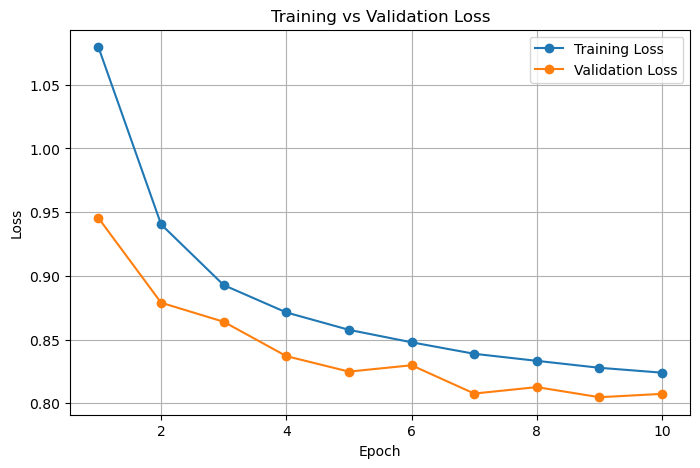

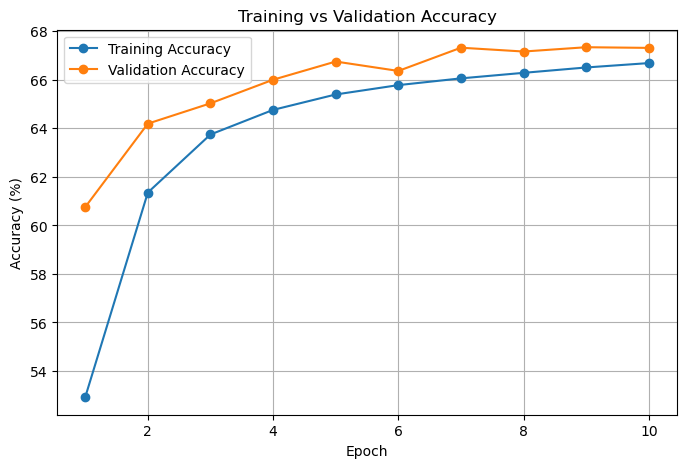

In [22]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

## Loss graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

## Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## initail Model Evaluation

In [23]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import torch

model.eval()

all_predictions = []

with torch.no_grad():
    for i in range(0, len(X_test_tensor), 512):
        X_batch = X_test_tensor[i:i + 512]
        outputs = model(X_batch)
        predictions = outputs.argmax(dim=1)
        all_predictions.extend(predictions.cpu().numpy())

# Convert labels back from 0–3 to Severity 1–4
y_pred = np.array(all_predictions) + 1
y_true = y_test.to_numpy()

print("Test Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[1, 2, 3, 4],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred, labels=[1, 2, 3, 4]))

Test Accuracy: 44.55 %

Classification Report:
              precision    recall  f1-score   support

           1       0.06      0.90      0.11       674
           2       0.95      0.39      0.56     61570
           3       0.39      0.62      0.48     12993
           4       0.08      0.79      0.14      2047

    accuracy                           0.45     77284
   macro avg       0.37      0.68      0.32     77284
weighted avg       0.83      0.45      0.53     77284

Confusion Matrix:
[[  606    19    33    16]
 [ 7362 24121 12747 17340]
 [ 1952   958  8083  2000]
 [   90   221   114  1622]]


In [24]:
import copy
import torch.optim as optim

# Restore the best model from the previous training
model.load_state_dict(best_model_state)

# Reduce learning rate for fine-tuning
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0003
)

# Use the original loss because training classes are balanced
criterion = nn.CrossEntropyLoss()

print("Best model restored.")
print("New learning rate:", optimizer.param_groups[0]["lr"])
print("Loss function:", criterion)

Best model restored.
New learning rate: 0.0003
Loss function: CrossEntropyLoss()


## Fine Tuning

In [25]:
import copy
import torch

num_epochs = 10
patience = 3

best_finetune_loss = float("inf")
best_finetune_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

finetune_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        batch_size = y_batch.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (
            outputs.argmax(dim=1) == y_batch
        ).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_accuracy = 100 * train_correct / train_total

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            batch_size = y_batch.size(0)
            val_loss_sum += loss.item() * batch_size
            val_correct += (
                outputs.argmax(dim=1) == y_batch
            ).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_accuracy = 100 * val_correct / val_total

    finetune_history["train_loss"].append(train_loss)
    finetune_history["train_accuracy"].append(train_accuracy)
    finetune_history["val_loss"].append(val_loss)
    finetune_history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}%"
    )

    if val_loss < best_finetune_loss:
        best_finetune_loss = val_loss
        best_finetune_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

model.load_state_dict(best_finetune_state)
print(f"\nBest fine-tuning validation loss: {best_finetune_loss:.4f}")
print("Best fine-tuned model restored.")

Epoch [1/10] | Train Loss: 0.8040 | Train Accuracy: 67.56% | Val Loss: 0.7825 | Val Accuracy: 68.38%
Epoch [2/10] | Train Loss: 0.7987 | Train Accuracy: 67.80% | Val Loss: 0.7843 | Val Accuracy: 68.37%
Epoch [3/10] | Train Loss: 0.7956 | Train Accuracy: 68.04% | Val Loss: 0.7827 | Val Accuracy: 68.38%
Epoch [4/10] | Train Loss: 0.7936 | Train Accuracy: 68.04% | Val Loss: 0.7764 | Val Accuracy: 68.70%
Epoch [5/10] | Train Loss: 0.7916 | Train Accuracy: 68.11% | Val Loss: 0.7786 | Val Accuracy: 68.63%
Epoch [6/10] | Train Loss: 0.7916 | Train Accuracy: 68.14% | Val Loss: 0.7738 | Val Accuracy: 68.78%
Epoch [7/10] | Train Loss: 0.7881 | Train Accuracy: 68.30% | Val Loss: 0.7795 | Val Accuracy: 68.68%
Epoch [8/10] | Train Loss: 0.7874 | Train Accuracy: 68.37% | Val Loss: 0.7708 | Val Accuracy: 68.93%
Epoch [9/10] | Train Loss: 0.7858 | Train Accuracy: 68.39% | Val Loss: 0.7717 | Val Accuracy: 68.77%
Epoch [10/10] | Train Loss: 0.7845 | Train Accuracy: 68.35% | Val Loss: 0.7725 | Val Accura

## insight
* Restored the best initial model.
* Reduced the learning rate to 0.0003.
* Continued training for up to 10 additional epochs.
* Selected the best model using validation loss.


Fine-tuning allows the model to make smaller weight updates and potentially improve its performance.

## Final Test Evaluation

In [26]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np
import torch

model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    y_pred = test_outputs.argmax(dim=1).cpu().numpy()

y_true = y_test_tensor.cpu().numpy()

print("Final Test Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")

print("\nClassification Report:\n")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=[
            "Severity 1",
            "Severity 2",
            "Severity 3",
            "Severity 4"
        ],
        zero_division=0
    )
)

print("\nConfusion Matrix:\n")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3]))

Final Test Accuracy: 46.38 %

Classification Report:

              precision    recall  f1-score   support

  Severity 1       0.07      0.89      0.13       674
  Severity 2       0.95      0.41      0.57     61570
  Severity 3       0.40      0.65      0.49     12993
  Severity 4       0.08      0.82      0.14      2047

    accuracy                           0.46     77284
   macro avg       0.38      0.69      0.34     77284
weighted avg       0.83      0.46      0.54     77284


Confusion Matrix:

[[  601    14    42    17]
 [ 6280 25154 12476 17660]
 [ 1607   988  8405  1993]
 [   49   228    87  1683]]


## insight

The model identifies many records belonging to Severity 1 and Severity 4, but their precision is low. This means many predictions for those classes are incorrect. The model needs further improvement before it can be considered reliable.

## Validation Evaluation

In [27]:
from sklearn.metrics import classification_report, confusion_matrix
import torch

model.eval()

val_predictions = []
val_actual = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        outputs = model(X_batch)
        predictions = outputs.argmax(dim=1)

        val_predictions.extend(predictions.cpu().numpy())
        val_actual.extend(y_batch.cpu().numpy())

print("Validation Classification Report:\n")
print(
    classification_report(
        val_actual,
        val_predictions,
        labels=[0, 1, 2, 3],
        target_names=[
            "Severity 1",
            "Severity 2",
            "Severity 3",
            "Severity 4"
        ],
        zero_division=0
    )
)

print("\nValidation Confusion Matrix:\n")
print(confusion_matrix(val_actual, val_predictions, labels=[0, 1, 2, 3]))

Validation Classification Report:

              precision    recall  f1-score   support

  Severity 1       0.78      0.89      0.83     10000
  Severity 2       0.65      0.40      0.50     10000
  Severity 3       0.68      0.64      0.66     10000
  Severity 4       0.63      0.82      0.71     10000

    accuracy                           0.69     40000
   macro avg       0.69      0.69      0.68     40000
weighted avg       0.69      0.69      0.68     40000


Validation Confusion Matrix:

[[8944  189  561  306]
 [1021 4040 2054 2885]
 [1218  805 6420 1557]
 [ 242 1201  388 8169]]


## insight

* Evaluated the model on the balanced validation set.
* Validation accuracy was approximately 69%.
* Compared precision, recall, and F1-score across all four classes.


Validation performance is better than test performance. The difference suggests that the model's generalization to the naturally imbalanced test set remains a challenge.

In [29]:
# Check overlap using a unique row identifier, not reset index values

train_ids = set(df_train_raw["ID"].astype(str))
test_ids = set(df_test_raw["ID"].astype(str))

print("Train unique IDs:", len(train_ids))
print("Test unique IDs:", len(test_ids))
print("Overlapping IDs:", len(train_ids.intersection(test_ids)))

Train unique IDs: 200000
Test unique IDs: 77284
Overlapping IDs: 0


In [30]:
print("Train feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)

print("\nPreprocessed train shape:", X_train_processed.shape)
print("Preprocessed test shape:", X_test_processed.shape)

print("\nTrain missing values:", X_train.isnull().sum().sum())
print("Test missing values:", X_test.isnull().sum().sum())

print("\nSame feature columns:", list(X_train.columns) == list(X_test.columns))
print("Same processed feature count:",
      X_train_processed.shape[1] == X_test_processed.shape[1])

Train feature shape: (200000, 28)
Test feature shape: (77284, 28)

Preprocessed train shape: (200000, 153)
Preprocessed test shape: (77284, 153)

Train missing values: 131371
Test missing values: 60866

Same feature columns: True
Same processed feature count: True


In [31]:
import numpy as np
import torch

def count_missing(data):
    if hasattr(data, "toarray"):
        data = data.toarray()
    else:
        data = np.asarray(data)

    return int(np.isnan(data).sum())

print("Processed train missing:", count_missing(X_train_processed))
print("Processed test missing:", count_missing(X_test_processed))

print("Train tensor contains NaN:", torch.isnan(X_train_tensor).any().item())
print("Test tensor contains NaN:", torch.isnan(X_test_tensor).any().item())

Processed train missing: 0
Processed test missing: 0
Train tensor contains NaN: False
Test tensor contains NaN: False


## Class distribution check

In [32]:
print("Training labels:")
print(y_train.value_counts().sort_index())

print("\nTest labels:")
print(y_test.value_counts().sort_index())

print("\nEncoded training labels:")
print(torch.bincount(y_train_tensor))

print("\nEncoded test labels:")
print(torch.bincount(y_test_tensor))

Training labels:
Severity
1    50000
2    50000
3    50000
4    50000
Name: count, dtype: int64

Test labels:
Severity
1      674
2    61570
3    12993
4     2047
Name: count, dtype: int64

Encoded training labels:
tensor([50000, 50000, 50000, 50000])

Encoded test labels:
tensor([  674, 61570, 12993,  2047])


## insight

* Confirmed that the training labels contain 50,000 records per class.
* Verified that the test labels retain the original imbalanced distribution.

    
The difference in class distributions is important when interpreting test accuracy and class-wise metrics.

In [33]:
from collections import Counter

model.eval()

all_predictions = []

with torch.no_grad():
    for X_batch, _ in DataLoader(
        TensorDataset(X_test_tensor, y_test_tensor),
        batch_size=512,
        shuffle=False
    ):
        outputs = model(X_batch)
        predictions = torch.argmax(outputs, dim=1)
        all_predictions.extend(predictions.cpu().numpy())

print("Actual test distribution (Severity 1-4):")
print(torch.bincount(y_test_tensor, minlength=4))

print("\nPredicted test distribution (Severity 1-4):")
print(Counter(all_predictions))

print("\nTotal predictions:", len(all_predictions))

Actual test distribution (Severity 1-4):
tensor([  674, 61570, 12993,  2047])

Predicted test distribution (Severity 1-4):
Counter({np.int64(1): 26384, np.int64(3): 21353, np.int64(2): 21010, np.int64(0): 8537})

Total predictions: 77284


In [34]:
import torch
import numpy as np

model.eval()

with torch.no_grad():
    logits = model(X_test_tensor)
    probabilities = torch.softmax(logits, dim=1)
    predictions = torch.argmax(probabilities, dim=1)

print("Mean predicted probability for each class:")
print(probabilities.mean(dim=0).cpu().numpy())

print("\nFirst 10 predictions (Severity 1-4):")
print((predictions[:10] + 1).cpu().numpy())

print("\nFirst 10 actual labels:")
print((y_test_tensor[:10] + 1).cpu().numpy())

Mean predicted probability for each class:
[0.11168641 0.37166798 0.26841152 0.24823412]

First 10 predictions (Severity 1-4):
[1 1 1 1 1 1 1 1 1 1]

First 10 actual labels:
[1 1 1 1 1 1 1 1 1 1]


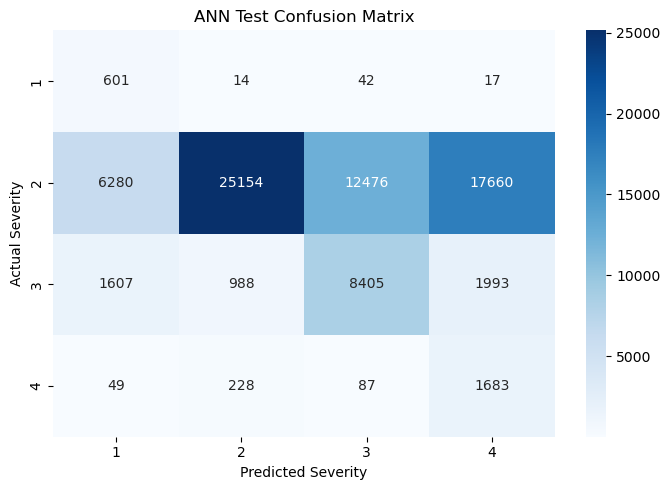

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Use the existing final test predictions and actual labels
cm = confusion_matrix(
    y_test_tensor.cpu().numpy(),
    predictions.cpu().numpy(),
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4],
    yticklabels=[1, 2, 3, 4]
)

plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.title("ANN Test Confusion Matrix")
plt.tight_layout()
plt.show()

## Confusion Matrix Interpretation

The confusion matrix shows how well the ANN model predicts the four accident severity classes.

Key Observations

- Severity 1: 601 cases were correctly classified.
- Severity 2: 25,154 cases were correctly classified.
- Severity 3: 8,405 cases were correctly classified.
- Severity 4: 1,683 cases were correctly classified.

The diagonal values represent correct predictions, while the values outside the diagonal represent misclassifications.

The model confuses several Severity 2 cases with Severity 3 and Severity 4. This indicates that the model has difficulty distinguishing some severity levels.


## Saving the model

In [40]:
import os
import torch
import joblib

# Folder to save the model files
save_dir = "saved_model"
os.makedirs(save_dir, exist_ok=True)

# Save the trained model
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_size": X_train_tensor.shape[1],
        "num_classes": 4
    },
    os.path.join(save_dir, "accident_severity_model.pth")
)

# Save the fitted preprocessing pipeline
joblib.dump(
    preprocessor,
    os.path.join(save_dir, "preprocessor.joblib")
)

# Save the feature names in the exact training order
joblib.dump(
    feature_columns,
    os.path.join(save_dir, "feature_columns.joblib")
)

print("Model and preprocessing files saved successfully!")
print("Saved files:", os.listdir(save_dir))

Model and preprocessing files saved successfully!
Saved files: ['accident_severity_model.pth', 'feature_columns.joblib', 'preprocessor.joblib']


In [42]:
## load and test the saved model

import os
import torch
import joblib
import numpy as np

# Load saved files
saved_model = torch.load(
    os.path.join(save_dir, "accident_severity_Model.Pth"),
    map_location="cpu"
)

loaded_preprocessor = joblib.load(
    os.path.join(save_dir, "preprocessor.joblib")
)

loaded_features = joblib.load(
    os.path.join(save_dir, "feature_columns.joblib")
)

# Rebuild and load the model
loaded_model = AccidentSeverityANN(
    saved_model["input_size"],
    saved_model["num_classes"]
)

loaded_model.load_state_dict(saved_model["model_state_dict"])
loaded_model.eval()

# Test with 5 unseen test rows
sample_raw = X_test.iloc[:5][loaded_features]
sample_processed = loaded_preprocessor.transform(sample_raw)

if hasattr(sample_processed, "toarray"):
    sample_processed = sample_processed.toarray()

sample_tensor = torch.tensor(
    np.asarray(sample_processed),
    dtype=torch.float32
)

with torch.no_grad():
    outputs = loaded_model(sample_tensor)
    predicted_severity = outputs.argmax(dim=1).numpy() + 1

print("Model loaded successfully!")
print("Input features:", len(loaded_features))
print("Predicted severity:", predicted_severity)
print("Actual severity:", y_test.iloc[:5].to_numpy())

Model loaded successfully!
Input features: 28
Predicted severity: [1 1 1 1 1]
Actual severity: [1 1 1 1 1]


## conclusion

This project demonstrates the development of an AI-based road accident severity prediction system using the US Accidents dataset and a PyTorch Artificial Neural Network. The workflow includes data sampling, feature engineering, preprocessing, model training, fine-tuning, evaluation, and model saving.
The final model achieved approximately 46.38% test accuracy, with different levels of performance across the four severity classes. Although the balanced training dataset helped the model learn from every class, its performance on the naturally imbalanced test set indicates that further improvements are necessary. Future work can explore class-weighted loss functions, alternative sampling strategies, additional model architectures, and more detailed evaluation.
Finally, the trained model and preprocessing pipeline were saved and successfully reloaded for prediction. These files provide the foundation for developing a Streamlit application where users can enter accident-related details and obtain a predicted severity class.
Overall, this project provides practical experience in data preprocessing, feature engineering, deep learning, model evaluation, and deploying a machine learning model for a real-world classification problem.